# Eksperimen Machine Learning - Breast Cancer Dataset

**Nama:** gaji  
**Dataset:** Breast Cancer Wisconsin  
**Objective:** Melakukan eksplorasi dan preprocessing dataset Breast Cancer untuk klasifikasi biner (benign/malignant)  

## Tahapan Eksperimen:
1. Data Loading
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing
4. Menyimpan Dataset yang Telah Dipreprocessing

---

## 1. Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

print('Libraries imported successfully!')

Libraries imported successfully!


In [2]:
# Load dataset
df = pd.read_csv('../breast_cancer_raw/breast_cancer.csv')

print(f'Dataset Shape: {df.shape}')
print(f'\nKolom: {list(df.columns)}')
print(f'\nTipe Data:\n{df.dtypes}')
df.head(10)

Dataset Shape: (569, 31)

Kolom: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']

Tipe Data:
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error       

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0
5,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,...,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440,0
6,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,...,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.1932,0.3063,0.08368,0
7,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,0.07451,...,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.1556,0.3196,0.11510,0
8,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,...,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.2060,0.4378,0.10720,0
9,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,0.08243,...,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.2210,0.4366,0.20750,0


In [3]:
# Info dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

## 2. Exploratory Data Analysis (EDA)

In [4]:
# Statistik deskriptif
df.describe().round(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,...,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000,569.000
mean,14.127,19.290,91.969,654.889,0.096,0.104,0.089,0.049,0.181,0.063,...,25.677,107.261,880.583,0.132,0.254,0.272,0.115,0.290,0.084,0.627
std,3.524,4.301,24.299,351.914,0.014,0.053,0.080,0.039,0.027,0.007,...,6.146,33.603,569.357,0.023,0.157,0.209,0.066,0.062,0.018,0.484
min,6.981,9.710,43.790,143.500,0.053,0.019,0.000,0.000,0.106,0.050,...,12.020,50.410,185.200,0.071,0.027,0.000,0.000,0.156,0.055,0.000
25%,11.700,16.170,75.170,420.300,0.086,0.065,0.030,0.020,0.162,0.058,...,21.080,84.110,515.300,0.117,0.147,0.114,0.065,0.250,0.071,0.000
50%,13.370,18.840,86.240,551.100,0.096,0.093,0.062,0.034,0.179,0.062,...,25.410,97.660,686.500,0.131,0.212,0.227,0.100,0.282,0.080,1.000
75%,15.780,21.800,104.100,782.700,0.105,0.130,0.131,0.074,0.196,0.066,...,29.720,125.400,1084.000,0.146,0.339,0.383,0.161,0.318,0.092,1.000
max,28.110,39.280,188.500,2501.000,0.163,0.345,0.427,0.201,0.304,0.097,...,49.540,251.200,4254.000,0.223,1.058,1.252,0.291,0.664,0.208,1.000


In [5]:
# Cek missing values
print('Missing Values per Kolom:')
print(df.isnull().sum())
print(f'\nTotal Missing Values: {df.isnull().sum().sum()}')

Missing Values per Kolom:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Total Missing Values: 0


In [6]:
# Cek duplikat
print(f'Jumlah duplikat: {df.duplicated().sum()}')

Jumlah duplikat: 0


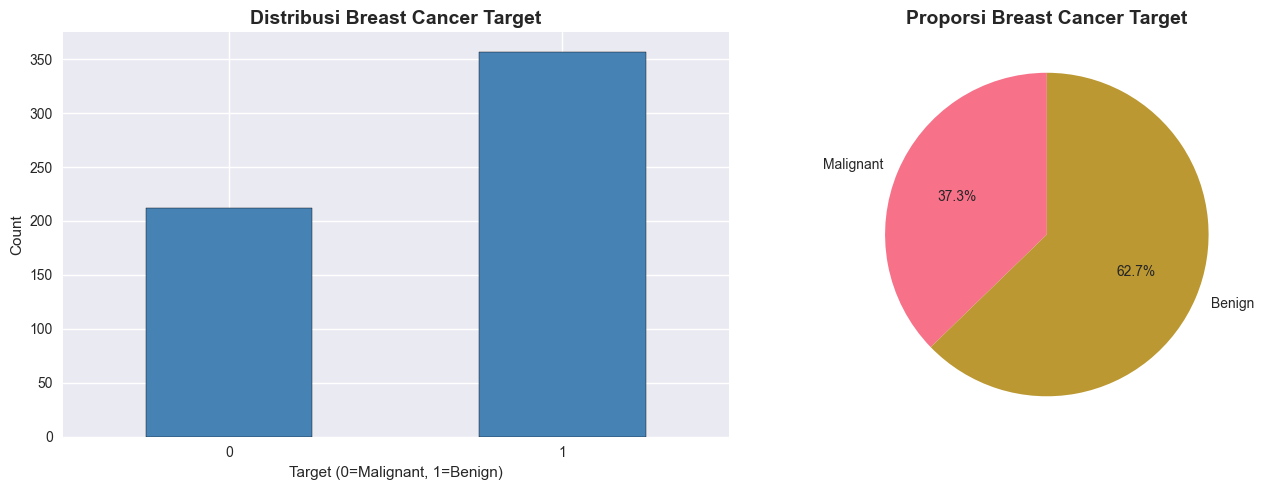

In [7]:
# Distribusi target
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar plot
df['target'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title('Distribusi Breast Cancer Target', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Target (0=Malignant, 1=Benign)')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)

# Pie chart
df['target'].value_counts().sort_index().plot(kind='pie', ax=axes[1], autopct='%1.1f%%', startangle=90,
                                              labels=['Malignant', 'Benign'])
axes[1].set_title('Proporsi Breast Cancer Target', fontsize=14, fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

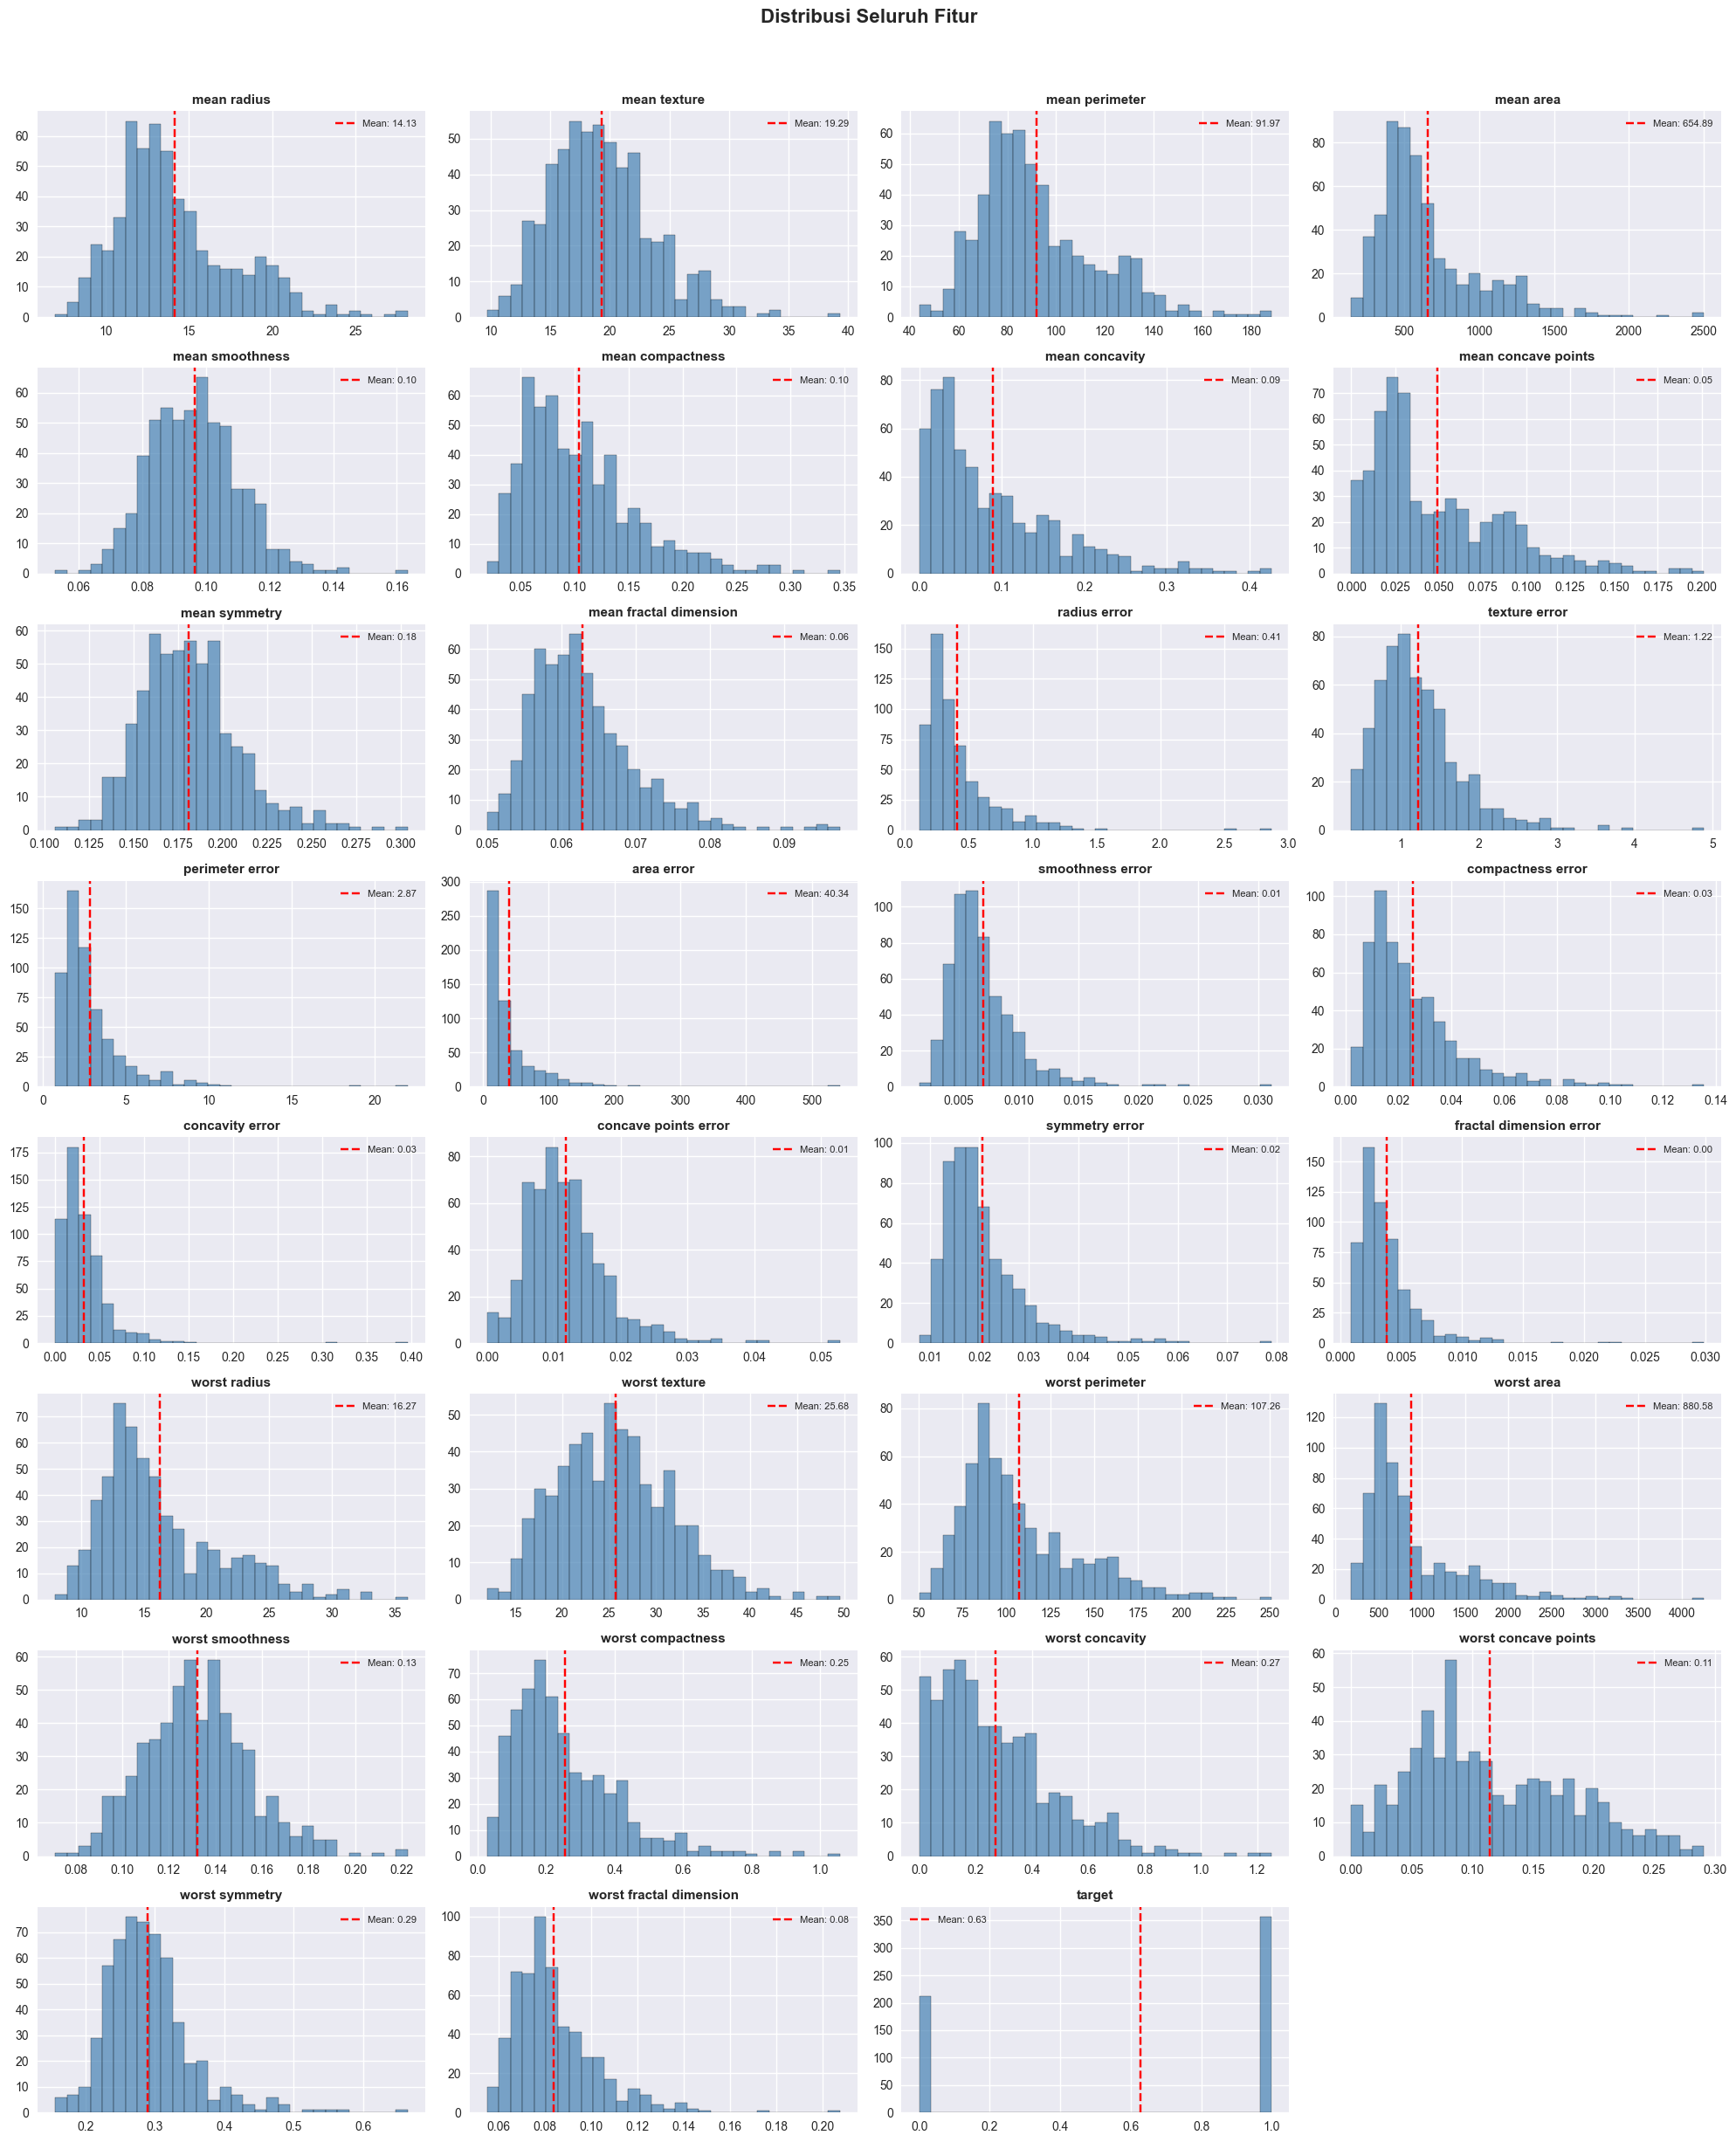

In [8]:
# Distribusi fitur
num_features = len(df.columns)
n_cols = 4
n_rows = (num_features + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(df.columns):
    axes[i].hist(df[col], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean: {df[col].mean():.2f}')
    axes[i].legend(fontsize=8)

# Hide empty subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distribusi Seluruh Fitur', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

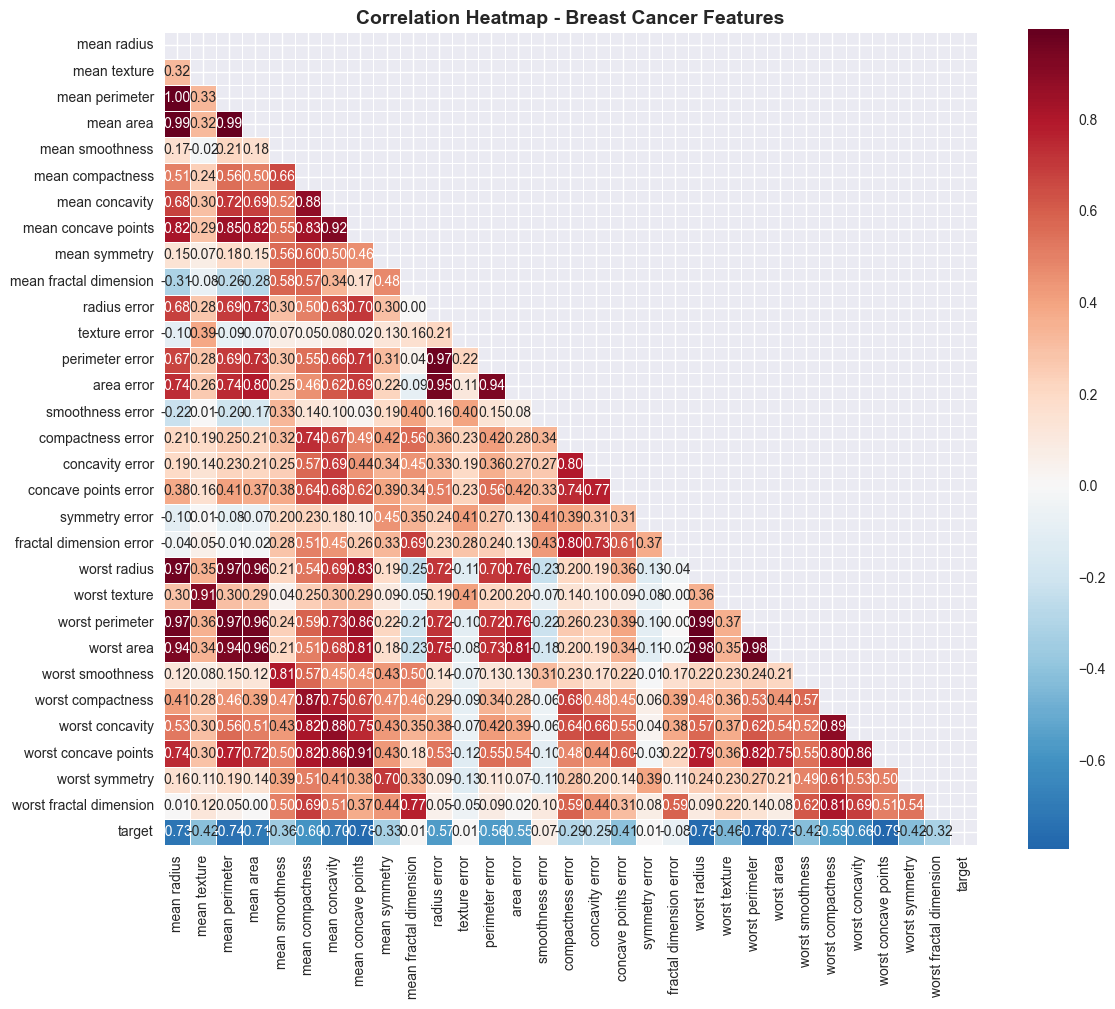

In [9]:
# Correlation heatmap
plt.figure(figsize=(12, 10))
corr_matrix = df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', 
            center=0, square=True, linewidths=0.5)
plt.title('Correlation Heatmap - Breast Cancer Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

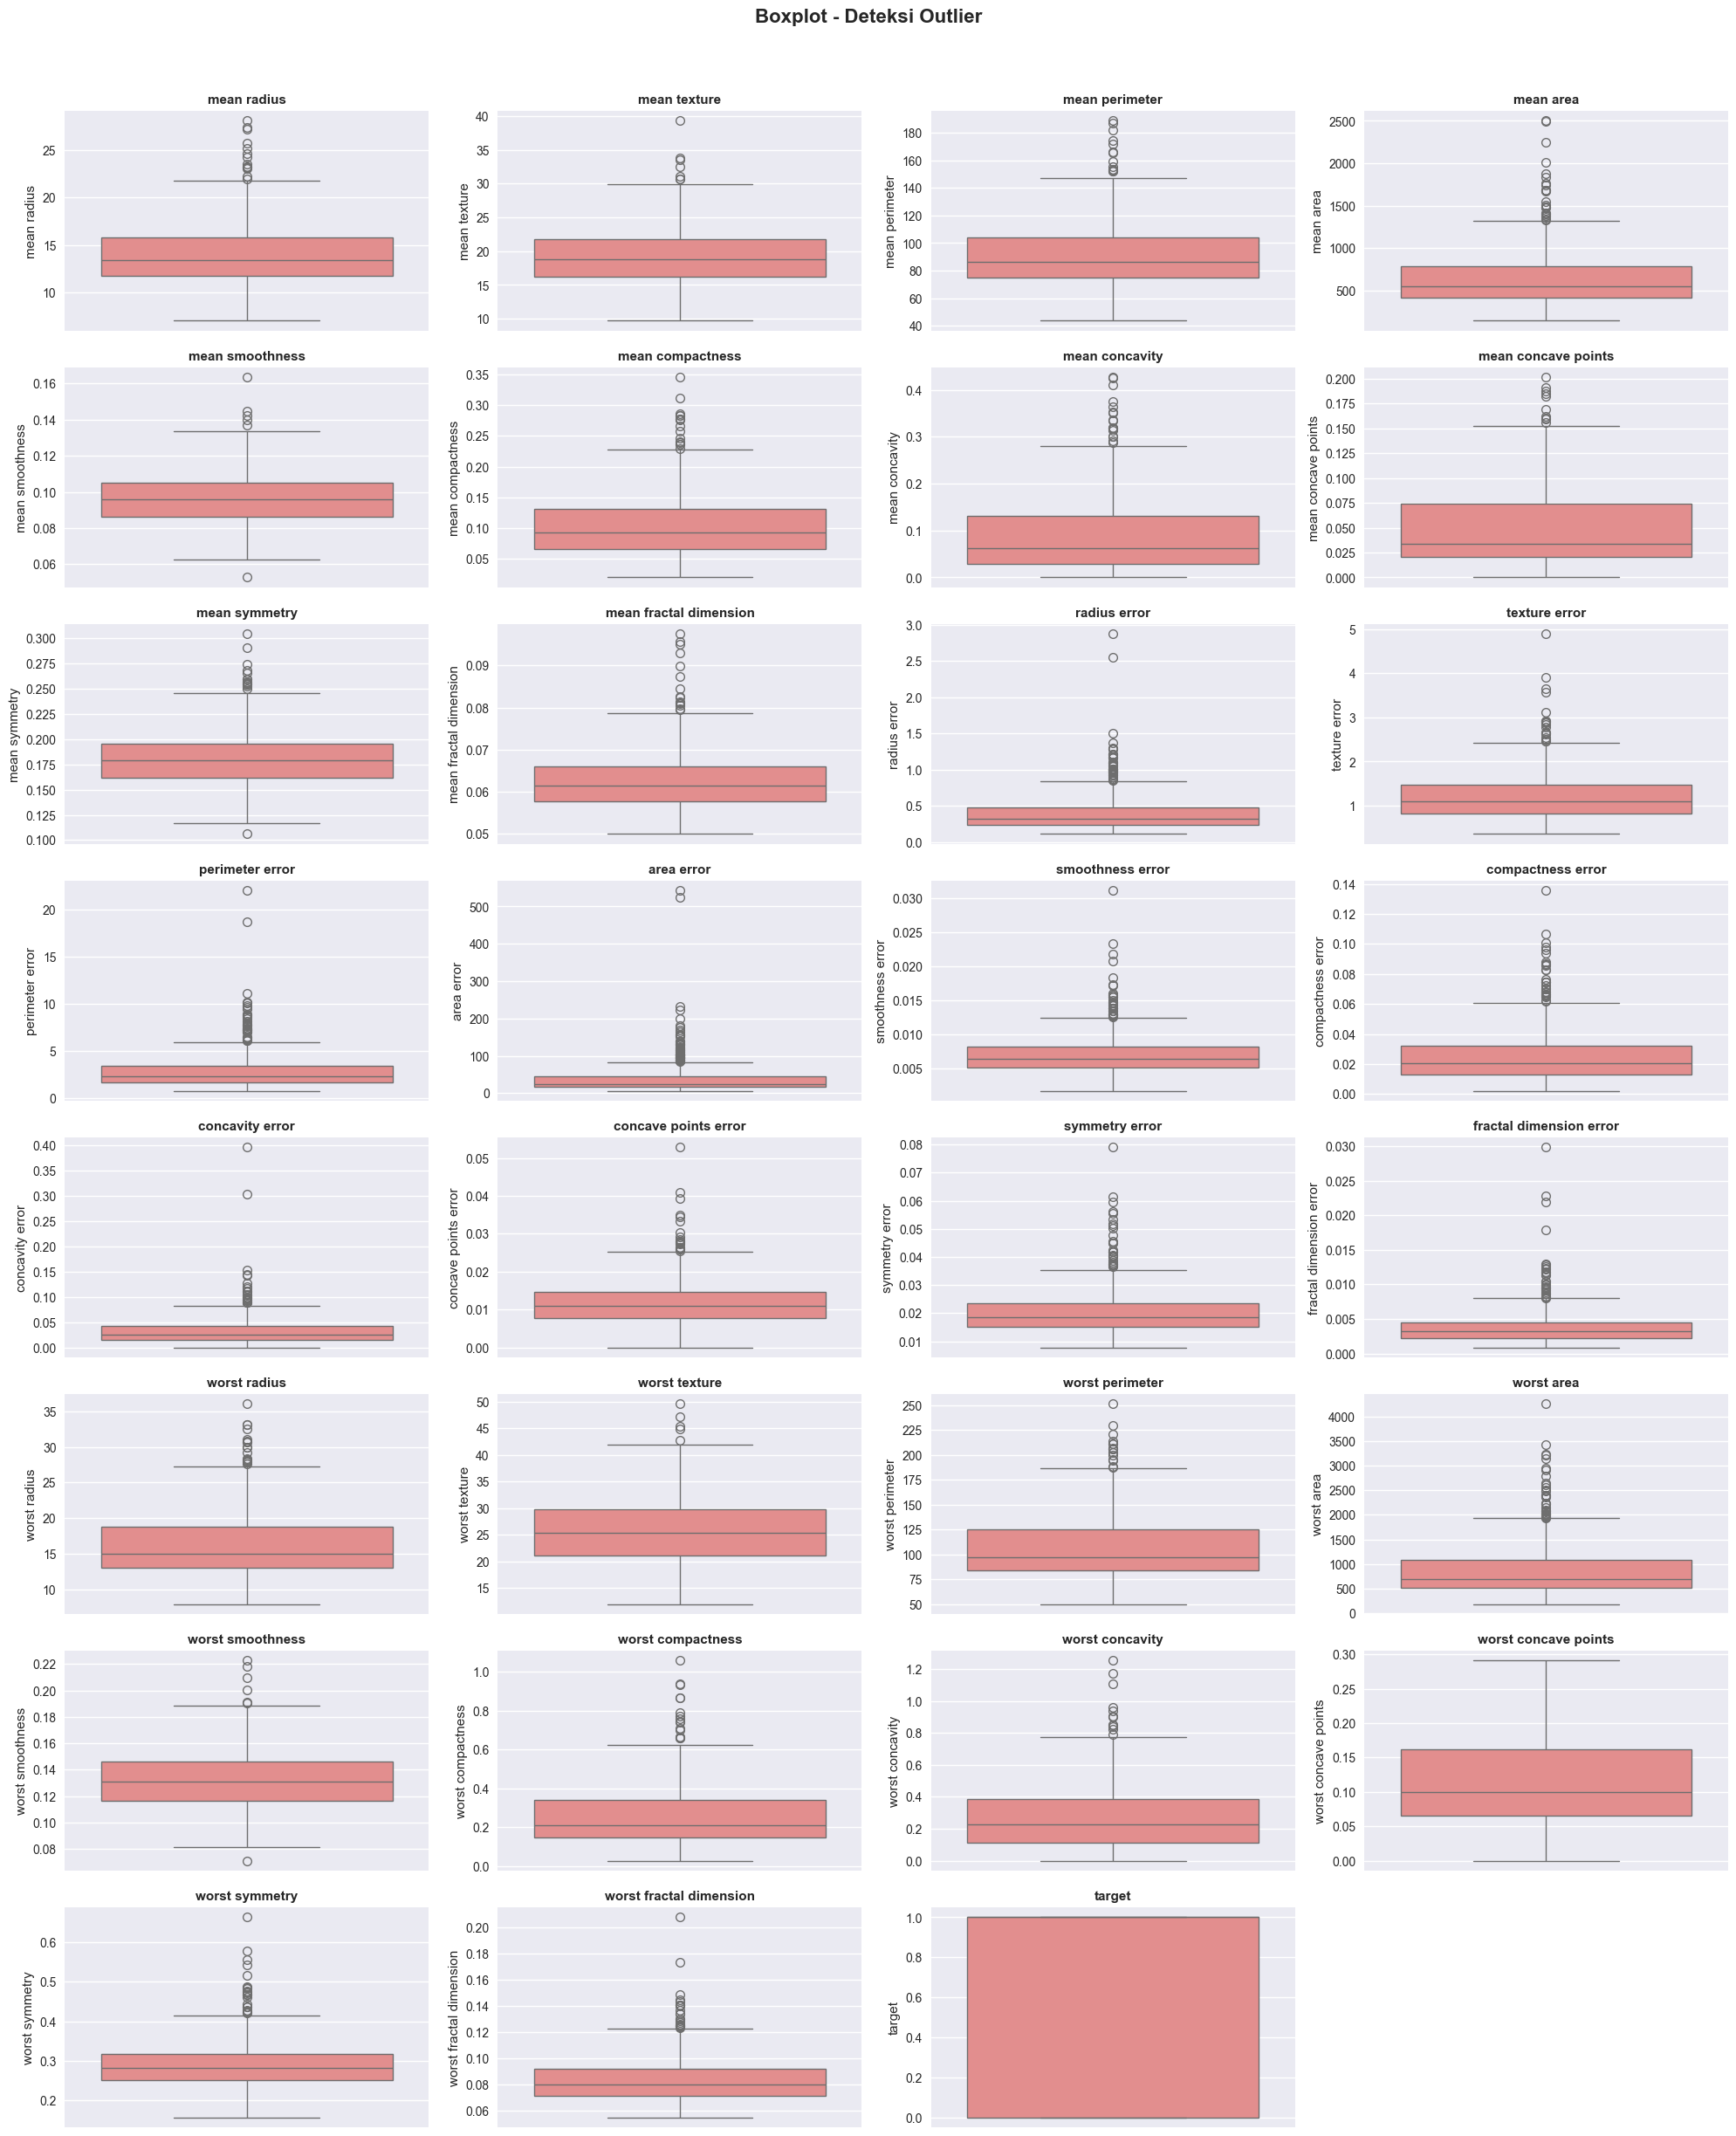

In [10]:
# Boxplot untuk deteksi outlier
num_features = len(df.columns)
n_cols = 4
n_rows = (num_features + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(df.columns):
    sns.boxplot(data=df, y=col, ax=axes[i], color='lightcoral')
    axes[i].set_title(col, fontsize=11, fontweight='bold')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Boxplot - Deteksi Outlier', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

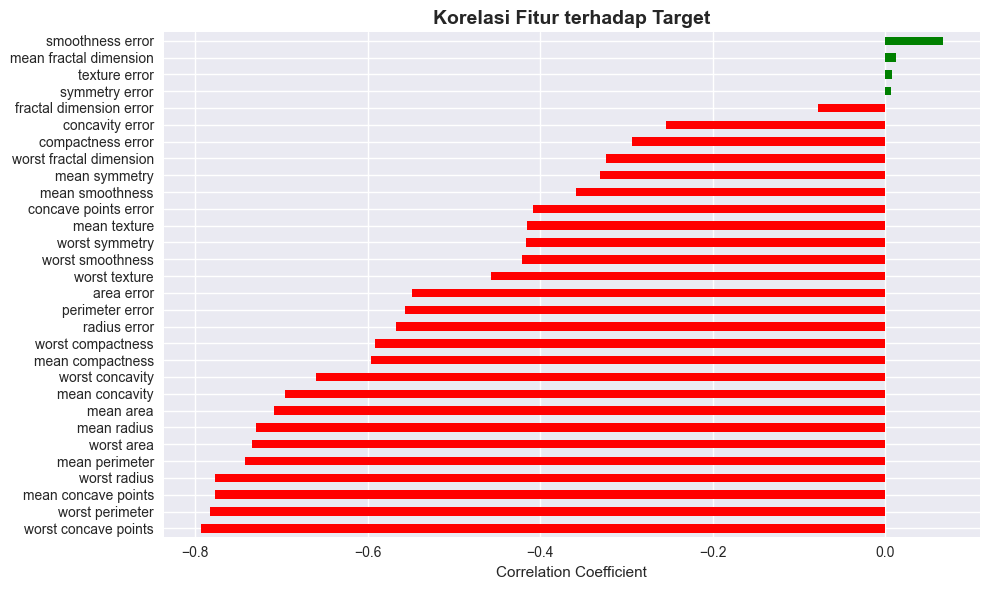

In [11]:
# Korelasi fitur terhadap target
plt.figure(figsize=(10, 6))
target_corr = df.corr()['target'].drop('target').sort_values()
target_corr.plot(kind='barh', color=['red' if x < 0 else 'green' for x in target_corr])
plt.title('Korelasi Fitur terhadap Target', fontsize=14, fontweight='bold')
plt.xlabel('Correlation Coefficient')
plt.tight_layout()
plt.show()

## 3. Data Preprocessing

In [12]:
# Copy dataframe
df_processed = df.copy()
print(f'Shape awal: {df_processed.shape}')

Shape awal: (569, 31)


In [13]:
# Handle missing values (jika ada)
missing = df_processed.isnull().sum().sum()
print(f'Missing values: {missing}')

if missing > 0:
    numeric_cols = df_processed.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        df_processed[col].fillna(df_processed[col].median(), inplace=True)
    print(f'Missing values setelah treatment: {df_processed.isnull().sum().sum()}')
else:
    print('Tidak ada missing values.')

Missing values: 0
Tidak ada missing values.


In [14]:
# Remove duplicates
print(f'Duplikat sebelum: {df_processed.duplicated().sum()}')
df_processed = df_processed.drop_duplicates().reset_index(drop=True)
print(f'Shape setelah hapus duplikat: {df_processed.shape}')

Duplikat sebelum: 0
Shape setelah hapus duplikat: (569, 31)


In [15]:
# Handle outliers menggunakan IQR clipping
feature_cols = [col for col in df_processed.columns if col != 'target']

for col in feature_cols:
    Q1 = df_processed[col].quantile(0.25)
    Q3 = df_processed[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = ((df_processed[col] < lower) | (df_processed[col] > upper)).sum()
    if outliers > 0:
        df_processed[col] = df_processed[col].clip(lower=lower, upper=upper)
        print(f'{col}: {outliers} outlier(s) clipped to [{lower:.2f}, {upper:.2f}]')

mean radius: 14 outlier(s) clipped to [5.58, 21.90]
mean texture: 7 outlier(s) clipped to [7.73, 30.24]
mean perimeter: 13 outlier(s) clipped to [31.78, 147.49]
mean area: 25 outlier(s) clipped to [-123.30, 1326.30]
mean smoothness: 6 outlier(s) clipped to [0.06, 0.13]
mean compactness: 16 outlier(s) clipped to [-0.03, 0.23]
mean concavity: 18 outlier(s) clipped to [-0.12, 0.28]
mean concave points: 10 outlier(s) clipped to [-0.06, 0.15]
mean symmetry: 15 outlier(s) clipped to [0.11, 0.25]
mean fractal dimension: 15 outlier(s) clipped to [0.05, 0.08]
radius error: 38 outlier(s) clipped to [-0.14, 0.85]
texture error: 20 outlier(s) clipped to [-0.13, 2.43]
perimeter error: 38 outlier(s) clipped to [-1.02, 5.98]
area error: 65 outlier(s) clipped to [-23.16, 86.20]
smoothness error: 30 outlier(s) clipped to [0.00, 0.01]
compactness error: 28 outlier(s) clipped to [-0.02, 0.06]
concavity error: 22 outlier(s) clipped to [-0.03, 0.08]
concave points error: 19 outlier(s) clipped to [-0.00, 0.

In [16]:
# Pisahkan fitur dan target
X = df_processed.drop('target', axis=1)
y = df_processed['target']

print(f'Fitur shape: {X.shape}')
print(f'Target shape: {y.shape}')
print(f'\nDistribusi target:')
print(y.value_counts())
print(f'\nPersentase Benign: {y.mean()*100:.1f}%')

Fitur shape: (569, 30)
Target shape: (569,)

Distribusi target:
target
1    357
0    212
Name: count, dtype: int64

Persentase Benign: 62.7%


In [17]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'X_train: {X_train.shape}')
print(f'X_test: {X_test.shape}')
print(f'y_train distribution:\n{y_train.value_counts()}')
print(f'y_test distribution:\n{y_test.value_counts()}')

X_train: (455, 30)
X_test: (114, 30)
y_train distribution:
target
1    285
0    170
Name: count, dtype: int64
y_test distribution:
target
1    72
0    42
Name: count, dtype: int64


In [18]:
# Feature scaling
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), 
    columns=X_train.columns, 
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), 
    columns=X_test.columns, 
    index=X_test.index
)

print('Feature scaling selesai!')
print(f'\nStatistik X_train_scaled:')
X_train_scaled.describe().round(3)

Feature scaling selesai!



Statistik X_train_scaled:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,455.000,455.000,455.000,455.000,455.000,455.000,455.000,455.000,455.000,455.000,...,455.000,455.000,455.000,455.000,455.000,455.000,455.000,455.000,455.000,455.000
mean,0.000,0.000,0.000,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,-0.000,...,-0.000,0.000,-0.000,0.000,-0.000,0.000,0.000,-0.000,0.000,-0.000
std,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,...,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001,1.001
min,-2.106,-2.228,-2.055,-1.617,-2.537,-1.680,-1.154,-1.271,-2.601,-1.949,...,-1.792,-2.226,-1.753,-1.396,-2.699,-1.539,-1.341,-1.707,-2.373,-1.762
25%,-0.712,-0.752,-0.714,-0.721,-0.727,-0.784,-0.783,-0.736,-0.693,-0.760,...,-0.678,-0.741,-0.706,-0.696,-0.735,-0.719,-0.811,-0.757,-0.696,-0.713
50%,-0.222,-0.090,-0.226,-0.306,-0.033,-0.234,-0.360,-0.407,-0.077,-0.181,...,-0.262,-0.035,-0.269,-0.335,-0.036,-0.264,-0.211,-0.250,-0.109,-0.208
75%,0.518,0.588,0.543,0.445,0.661,0.556,0.595,0.684,0.572,0.560,...,0.536,0.616,0.592,0.410,0.633,0.603,0.554,0.728,0.580,0.551
max,2.364,2.591,2.442,2.277,2.839,2.546,2.583,2.823,2.501,2.485,...,2.488,2.796,2.554,2.333,2.617,2.610,2.524,2.655,2.368,2.483


## 4. Menyimpan Dataset yang Telah Dipreprocessing

In [19]:
# Save preprocessed data
import os
output_dir = 'breast_cancer_preprocessing'
os.makedirs(output_dir, exist_ok=True)

X_train_scaled.to_csv(os.path.join(output_dir, 'X_train.csv'), index=False)
X_test_scaled.to_csv(os.path.join(output_dir, 'X_test.csv'), index=False)
y_train.to_csv(os.path.join(output_dir, 'y_train.csv'), index=False)
y_test.to_csv(os.path.join(output_dir, 'y_test.csv'), index=False)

print(f'Data preprocessed disimpan di: {output_dir}/')
print('Files:', os.listdir(output_dir))
print(f'\nX_train shape: {X_train_scaled.shape}')
print(f'X_test shape: {X_test_scaled.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_test shape: {y_test.shape}')

Data preprocessed disimpan di: breast_cancer_preprocessing/
Files: ['metadata.json', 'scaler_info.json', 'X_test.csv', 'X_train.csv', 'y_test.csv', 'y_train.csv']

X_train shape: (455, 30)
X_test shape: (114, 30)
y_train shape: (455,)
y_test shape: (114,)


## Kesimpulan

- Dataset Breast Cancer memiliki 569 sampel dengan 30 fitur numerik dan 1 kolom target
- Tidak ditemukan missing values
- Terdapat beberapa duplikat yang sudah dihapus
- Outlier ditangani menggunakan IQR clipping
- Target berupa klasifikasi biner: Benign (1) dan Malignant (0)
- Data dibagi menjadi train (80%) dan test (20%) dengan stratified sampling
- Feature scaling dilakukan menggunakan StandardScaler
- Dataset yang telah dipreprocessing disimpan dalam format CSV untuk digunakan pada tahap selanjutnya